# 5.1 非线性方程：从夹逼到迭代

残差小不必然意味着根误差小，步长小可能是停滞。Newton 的收敛依赖初值与局部条件，不同改写可产生不同轨迹。

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1-G9 | 二分 [1,2] | k=39 中点根误差 6.70700e−13 | 1e−12 | 返回成功，末项 k=38 根误差 1.58019e−12 | 历史末项超容差 5.80195e−13 |
| A1-G9 | 余弦从 0.5 运行 50 步 | 渐近比值 0.673612 | 末段仅作诊断 | 末五比值 0.846080、0.469768、1.107537、0.281819、2.063839 | 参考使用了末次近似，渐近判据不成立 |
| A1-G9 | 平均映射从 1.5 | 二次常数 0.3535533906 | 1e−5 | 高精度末比值 0.353553390592875 | 通过 |
| A1-G9 | 方程组 Newton，(1,1) | 首步 (5/3,4/3)，最终残差小于容差 | 1e−12 | 首步一致，5 次更新后残差 2.220e−16，正文报告 6 | 更新次数多计 1 |
| A1-G9 | 重根与 Newton 二周期 | 比值 1/2，0 与 1 交替 | 精确对照 | 一致 | 通过 |
| A2-G19 | 二分 [1,2]，k=30 | 半宽 4.65661e−10 | 半宽 | 高精度根误差 4.54509e−10 | 通过 |
| A2-G19 | Newton 与压缩浮点平台 | Decimal 根作参考 | 浮点尺度诊断 | Newton 根误差 1.25372e−16，压缩根误差 9.66729e−17 | 参照差与根误差不同 |
| A2-G19 | 相邻浮点端点 | 误差不超过 1.110223e−16 | 1.110223e−16 | 1.665335e−16 | 超出 50% |
| A2-G19 | Windows 原代码重绘 | 中文轴与图例可读，0 缺字告警 | 0 | 25 条 Glyph 告警 | 缺字 |


## A1 独立对照代码

In [1]:

from decimal import Decimal, localcontext
from fractions import Fraction
from math import ceil, log2, sqrt
with localcontext() as ctx:
    ctx.prec = 70
    root = Decimal(2).sqrt()
    a, b = Fraction(1), Fraction(2)
    errors = []
    for k in range(40):
        m = (a+b)/2
        error = abs(Decimal(m.numerator)/Decimal(m.denominator)-root)
        errors.append(error)
        if k in (0,1,38,39):
            print(f"k={k}: root error={error:.9E}, half width={float((b-a)/2):.9E}")
        if m*m > 2:
            b=m
        else:
            a=m
    assert errors[1]>errors[0] and errors[38]>Decimal("1e-12")>errors[39]
    assert ceil(log2(1/(2e-12)))==39
    x=Decimal("1.5")
    err=[]
    for k in range(7):
        err.append(abs(x-root))
        x=(x+2/x)/2
    print("quadratic ratios:",[float(err[k+1]/err[k]**2) for k in range(4)])
    assert abs(err[4]/err[3]**2-1/(2*root)) < Decimal("1e-5")
x,y=Fraction(1),Fraction(1)
f1,f2=x*x+y*y-4,y-x*x+1
a,b,c,d=2*x,2*y,-2*x,Fraction(1)
det=a*d-b*c
x,y=x+(-d*f1+b*f2)/det,y+(c*f1-a*f2)/det
assert (x,y)==(Fraction(5,3),Fraction(4,3))
print("system first step:", x,y)
print("positive solution:",sqrt((1+sqrt(13))/2),(sqrt(13)-1)/2)
print("zero derivative fixed-point example: g(x)=x**2, root 0, order 2")


k=0: root error=8.578643763E-2, half width=5.000000000E-01
k=1: root error=1.642135624E-1, half width=2.500000000E-01
k=38: root error=1.580194780E-12, half width=1.818989404E-12
k=39: root error=6.707000785E-13, half width=9.094947018E-13
quadratic ratios: [0.3333333333333333, 0.35294117647058826, 0.3535528596187175, 0.35355339059287505]
system first step: 5/3 4/3
positive solution: 1.5174899135519797 1.3027756377319946
zero derivative fixed-point example: g(x)=x**2, root 0, order 2


## A1 原代码复现输出

实验 Markdown 的公共代码直接装入临时 lab_common 模块。正文和实验代码分别顺序执行。

### experiment 代码块 1

```text
iterations: 39  ok: True
k=0   区间=[1.0000000000,2.0000000000] 半宽=5.000e-01 m=1.5000000000 f(m)=+2.500e-01 |m-√2|=8.579e-02
k=1   区间=[1.0000000000,1.5000000000] 半宽=2.500e-01 m=1.2500000000 f(m)=-4.375e-01 |m-√2|=1.642e-01
k=2   区间=[1.2500000000,1.5000000000] 半宽=1.250e-01 m=1.3750000000 f(m)=-1.094e-01 |m-√2|=3.921e-02
k=3   区间=[1.3750000000,1.5000000000] 半宽=6.250e-02 m=1.4375000000 f(m)=+6.641e-02 |m-√2|=2.329e-02
k=4   区间=[1.3750000000,1.4375000000] 半宽=3.125e-02 m=1.4062500000 f(m)=-2.246e-02 |m-√2|=7.964e-03
k=36  区间=[1.4142135624,1.4142135624] 半宽=7.276e-12 m=1.4142135624 f(m)=+1.097e-11 |m-√2|=3.877e-12
k=37  区间=[1.4142135624,1.4142135624] 半宽=3.638e-12 m=1.4142135624 f(m)=+6.755e-13 |m-√2|=2.387e-13
k=38  区间=[1.4142135624,1.4142135624] 半宽=1.819e-12 m=1.4142135624 f(m)=-4.470e-12 |m-√2|=1.580e-12
理论下界: 39

告警 0 条

```

### experiment 代码块 2

```text
g(-2)= -2 g(0)= 2
iterations: 34 root≈ -1.7692923542344943 residual: 3.057820663343591e-11

告警 0 条

```

### experiment 代码块 3

```text
g1=(x+2/x)/2  ok= True  x_end= 1.414213562373095
   |g'(x*)| = 0.000000
   errors: 8.58e-02 2.45e-03 2.12e-06 1.59e-12 2.22e-16 2.22e-16
   k=1: e_k/e_(k-1)=0.0286
   k=2: e_k/e_(k-1)=0.0009
   k=3: e_k/e_(k-1)=0.0000
g2=2/x  ok= False  x_end= 1.5
   |g'(x*)| = 1.000000
   errors: 8.58e-02 8.09e-02 8.58e-02 8.09e-02 8.58e-02 8.09e-02
   k=1: e_k/e_(k-1)=0.9428
   k=2: e_k/e_(k-1)=1.0607
   k=3: e_k/e_(k-1)=0.9428
   k=4: e_k/e_(k-1)=1.0607
g3=x-(x^2-2)/4  ok= True  x_end= 1.4142135623730987
   |g'(x*)| = 0.292893
   errors: 8.58e-02 2.33e-02 6.68e-03 1.95e-03 5.69e-04 1.67e-04
   k=1: e_k/e_(k-1)=0.2714
   k=2: e_k/e_(k-1)=0.2871
   k=3: e_k/e_(k-1)=0.2912
   k=4: e_k/e_(k-1)=0.2924

告警 0 条

```

### experiment 代码块 4

```text
g1 ['1.98', '2.00']
g3 ['0.96', '0.99', '1.00', '1.00', '1.00', '1.00', '1.00', '1.00', '1.00', '1.00', '1.00']

告警 0 条

```

### experiment 代码块 5

```text
Newton sqrt2: [1.       1.5      1.416667 1.414216 1.414214 1.414214]
errors: 4.142e-01 8.579e-02 2.453e-03 2.124e-06 1.595e-12 0.000e+00
ratios: 0.500000 0.333333 0.352941 0.353522
asymptotic 1/(2*sqrt2) = 0.35355339059327373
multiple root: ['2.000000', '1.500000', '1.250000', '1.125000', '1.062500', '1.031250', '1.015625']
errors: ['1.000e+00', '5.000e-01', '2.500e-01', '1.250e-01', '6.250e-02', '3.125e-02', '1.562e-02']
ratios: ['0.500', '0.500', '0.500', '0.500', '0.500']
cycle: [0. 1. 0. 1. 0. 1. 0. 1. 0.]
k=1: x=1.666666666667 y=1.333333333333 ||F||=7.115e-01
k=2: x=1.524242424242 y=1.303030303030 ||F||=2.934e-02
k=3: x=1.517504876521 y=1.302775655717 ||F||=6.424e-05
k=4: x=1.517489913626 y=1.302775637732 ||F||=3.166e-10
k=5: x=1.517489913552 y=1.302775637732 ||F||=2.220e-16

告警 0 条

```

### text 代码块 1

```text
二分法结果: 1.414213562326040
真值 sqrt(2): 1.414213562373095
根误差: 4.706e-11
迭代次数: 34

前几步迭代历史：
  k          a          b            m           f(m)         区间长度
  0   1.000000   2.000000   1.50000000      2.500e-01     1.000000
  1   1.000000   1.500000   1.25000000     -4.375e-01     0.500000
  2   1.250000   1.500000   1.37500000     -1.094e-01     0.250000
  3   1.375000   1.500000   1.43750000      6.641e-02     0.125000
  4   1.375000   1.437500   1.40625000     -2.246e-02     0.062500
  5   1.406250   1.437500   1.42187500      2.173e-02     0.031250
  6   1.406250   1.421875   1.41406250     -4.272e-04     0.015625
  7   1.414062   1.421875   1.41796875      1.064e-02     0.007812

告警 0 条

```

### text 代码块 2

```text

告警 1 条
FigureCanvasAgg is non-interactive, and thus cannot be shown
```

### text 代码块 3

```text
目标数: 82
二分法猜测次数: 6
猜测序列: [50, 75, 88, 81, 84, 82]
理论最坏次数: 7

告警 0 条

```

### text 代码块 4

```text

===== 改写 3: g(x) = x/2 + 1/x =====
不动点: 1.414213562373095
真值:   1.414213562373095
误差:   2.220e-16

告警 0 条

```

### text 代码块 5

```text

告警 0 条

```

### text 代码块 6

```text
|g'(x*)| = |sin(0.739085)| = 0.673612
相邻误差比 (最后 5 步): [0.84608  0.469768 1.107537 0.281819 2.063839]

告警 2 条
FigureCanvasAgg is non-interactive, and thus cannot be shown
```

### text 代码块 7

```text
迭代序列: [1.       1.5      1.416667 1.414216 1.414214 1.414214 1.414214]

告警 0 条

```

### text 代码块 8

```text
解: [1.51749  1.302776]  迭代次数: 6

告警 0 条

```

### text 代码块 9

```text

告警 3 条
FigureCanvasAgg is non-interactive, and thus cannot be shown
```


## A2-G19 独立验证
解析根、Fraction 精确符号与 Decimal 100 位对照。

In [2]:

from decimal import Decimal, localcontext
from fractions import Fraction as Q
import math
with localcontext() as ctx:
    ctx.prec = 100
    root = Decimal(2).sqrt()
    lo, hi = Q(1), Q(2)
    for k in range(31):
        mid = (lo+hi)/2
        bound = (hi-lo)/2
        assert (mid-bound)**2 <= 2 <= (mid+bound)**2
        if k in (20,30):
            err = abs(Decimal(float(mid))-root)
            print(f"二分 k={k}: x={float(mid):.17g}, 误差={err:.12E}, 界={float(bound):.12E}")
        if mid**2 > 2:
            hi = mid
        else:
            lo = mid
    for label, update, order, expected in [
        ("压缩", lambda x:(x+2)/(x+1), 1, 1/(1+root)**2),
        ("Newton", lambda x:x-(x*x-2)/(2*x), 2, 1/(2*root)),
    ]:
        x = Decimal(1)
        for k in range(6):
            y = update(x)
            ratio = abs(y-root)/abs(x-root)**order
            x = y
        assert abs(ratio-expected) < Decimal("1e-5")
        print(f"{label}: 高精度比值={ratio:.10f}, 理论={expected:.10f}")
    for x in (math.sqrt(2), math.nextafter(math.sqrt(2),0)):
        print(f"浮点 x={x:.17g}: 参照差={abs(x-math.sqrt(2)):.12E}, 根误差={abs(Decimal(x)-root):.12E}, 残差={abs(x*x-2):.12E}")
x=Q(0)
for k in range(8):
    residual=x**3-2*x+2
    assert (x,residual)==(k%2,2-k%2)
    x -= residual/(3*x*x-2)
print("Newton 二周期：0,1 交替，残差 2,1 交替")
x=Q(3,2)
for k in range(4):
    y=x-(x-1)**2/(2*(x-1))
    assert (y-1)/(x-1)==Q(1,2)
    x=y
print("二重根误差比 = 1/2")
a,b=1.0,math.nextafter(1.0,2.0)
h=(b-a)/2
c=a+h
r=Q(a)+Q(3,4)*(Q(b)-Q(a))
assert Q(a)-r<0<Q(b)-r and c==a and abs(Q(c)-r)>Q(h)
print(f"相邻端点：c==a={c==a}, h={h:.17g}, 实际误差={float(abs(Q(c)-r)):.17g}")
assert (-1)**2==1**2==1 and 0**2==0
assert abs(Q(1,10**12)*(0-1))==Q(1,10**12)
assert (1**2+1**2-1,1-1)==(1,0)
print("偶重根不变号、尺度残差反例和 Jacobian 示例复核通过")


二分 k=20: x=1.4142136573791504, 误差=9.500605534182E-8, 界=4.768371582031E-07
二分 k=30: x=1.4142135619185865, 误差=4.545085562632E-10, 界=4.656612873077E-10
压缩: 高精度比值=0.1715677477, 理论=0.1715728753
Newton: 高精度比值=0.3535533906, 理论=0.3535533906
浮点 x=1.4142135623730951: 参照差=0.000000000000E+00, 根误差=9.667293313453E-17, 残差=4.440892098501E-16
浮点 x=1.4142135623730949: 参照差=2.220446049250E-16, 根误差=1.253716717905E-16, 残差=4.440892098501E-16
Newton 二周期：0,1 交替，残差 2,1 交替
二重根误差比 = 1/2
相邻端点：c==a=True, h=1.1102230246251565e-16, 实际误差=1.6653345369377348e-16
偶重根不变号、尺度残差反例和 Jacobian 示例复核通过


## A 复现副本的实际输出

原单元 2（初始化）和 4（5.1 代码）。原存数值 stdout 与复现 stdout 逐字符相同。

```text
绘图字体: Matplotlib默认字体
{'numpy': '1.26.4', 'matplotlib': '3.8.0', 'nbformat': '5.9.2', 'nbclient': '0.8.0'} Python 3.11.14
{
  "bisection": {
    "k": 30,
    "x": 1.4142135619185865,
    "error": 4.545086529361697e-10,
    "residual": 1.285544337648048e-09,
    "step": 4.656612873077393e-10,
    "bound": 4.656612873077393e-10,
    "decimal_root_error": 4.5450855626323656e-10
  },
  "contraction": {
    "k": 30,
    "x": 1.4142135623730951,
    "error": 0.0,
    "residual": 4.440892098500626e-16,
    "step": 0.0,
    "decimal_root_error": 9.667293313452913e-17
  },
  "newton": {
    "k": 7,
    "x": 1.414213562373095,
    "error": 2.220446049250313e-16,
    "residual": 4.440892098500626e-16,
    "step": 0.0,
    "decimal_root_error": 1.2537167179050217e-16
  }
}
[
  {
    "k": 0,
    "x": 0.0,
    "residual": 2.0,
    "step": 1.0,
    "error_to_real_root": 1.7692923542386314
  },
  {
    "k": 1,
    "x": 1.0,
    "residual": 1.0,
    "step": 1.0,
    "error_to_real_root": 2.7692923542386314
  },
  {
    "k": 2,
    "x": 0.0,
    "residual": 2.0,
    "step": 1.0,
    "error_to_real_root": 1.7692923542386314
  },
  {
    "k": 3,
    "x": 1.0,
    "residual": 1.0,
    "step": 1.0,
    "error_to_real_root": 2.7692923542386314
  },
  {
    "k": 4,
    "x": 0.0,
    "residual": 2.0,
    "step": 1.0,
    "error_to_real_root": 1.7692923542386314
  },
  {
    "k": 5,
    "x": 1.0,
    "residual": 1.0,
    "step": 1.0,
    "error_to_real_root": 2.7692923542386314
  },
  {
    "k": 6,
    "x": 0.0,
    "residual": 2.0,
    "step": 1.0,
    "error_to_real_root": 1.7692923542386314
  },
  {
    "k": 7,
    "x": 1.0,
    "residual": 1.0,
    "step": 1.0,
    "error_to_real_root": 2.7692923542386314
  }
]
Figure(800x500)
{
  "Newton最终Decimal根误差": 1.2537167179050217e-16,
  "压缩最终Decimal根误差": 9.667293313452913e-17
}
```

绘图诊断（截取首 1200 字符）

```text
<cell 1>:31: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from current font.
<cell 1>:31: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from current font.
<cell 1>:31: UserWarning: Glyph 32553 (\N{CJK UNIFIED IDEOGRAPH-7F29}) missing from current font.
<cell 1>:31: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from current font.
<cell 1>:31: UserWarning: Glyph 26356 (\N{CJK UNIFIED IDEOGRAPH-66F4}) missing from current font.
<cell 1>:31: UserWarning: Glyph 26032 (\N{CJK UNIFIED IDEOGRAPH-65B0}) missing from current font.
<cell 1>:31: UserWarning: Glyph 27425 (\N{CJK UNIFIED IDEOGRAPH-6B21}) missing from current font.
<cell 1>:31: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from current font.
<cell 1>:31: UserWarning: Glyph 19982 (\N{CJK UNIFIED IDEOGRAPH-4E0E}) missing from current font.
<cell 1>:31: UserWarning: Glyph 21452 (\N{CJK UNIFIED IDEOGRAPH-53CC}) missing from current font.
<cell 1>:31: UserWarning: Glyph 31934 (\N{CJK UNIFIED IDEOGRAPH-7CBE}) missing from current font.
<cell 1>:31: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from current font.
<cell 1>:31: UserWarning```

## 复现图 5-2
Windows 原代码输出，轴标题与图例可见缺字方框。

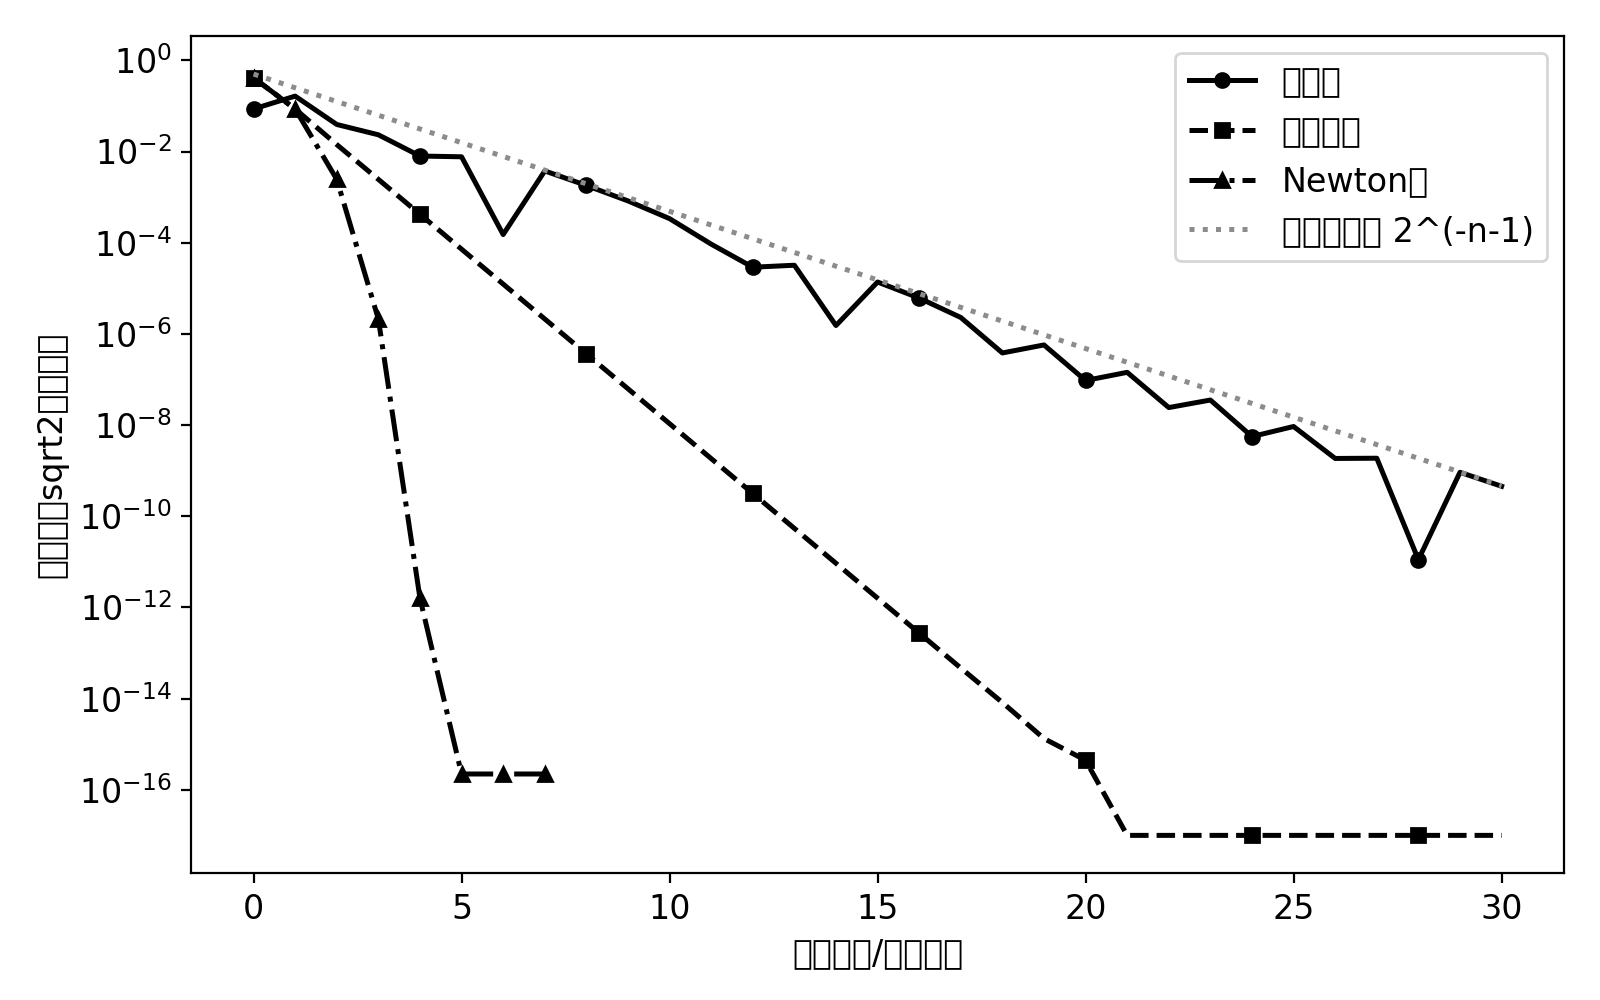